In [1]:
import pandas as pd

wine_df = pd.read_csv("winemag-data-130k-v2.csv", index_col=0)
wine_df["title"].head(10)

0                    Nicosia 2013 Vulkà Bianco  (Etna)
1        Quinta dos Avidagos 2011 Avidagos Red (Douro)
2        Rainstorm 2013 Pinot Gris (Willamette Valley)
3    St. Julian 2013 Reserve Late Harvest Riesling ...
4    Sweet Cheeks 2012 Vintner's Reserve Wild Child...
5    Tandem 2011 Ars In Vitro Tempranillo-Merlot (N...
6     Terre di Giurfo 2013 Belsito Frappato (Vittoria)
7                Trimbach 2012 Gewurztraminer (Alsace)
8    Heinz Eifel 2013 Shine Gewürztraminer (Rheinhe...
9    Jean-Baptiste Adam 2012 Les Natures Pinot Gris...
Name: title, dtype: object

In [2]:
wine_df["wine vintage"] = (
    wine_df["title"]
    .str.extract(r"\b((?:19|20)\d{2})\b", expand=False)
    .astype("Int64")
)

wine_df[["title", "wine vintage"]].head(10)

,title,wine vintage
0,Nicosia 2013 Vulkà Bianco (Etna),2013
1,Quinta dos Avidagos 2011 Avidagos Red (Douro),2011
2,Rainstorm 2013 Pinot Gris (Willamette Valley),2013
3,St. Julian 2013 Reserve Late Harvest Riesling ...,2013
4,Sweet Cheeks 2012 Vintner's Reserve Wild Child...,2012
5,Tandem 2011 Ars In Vitro Tempranillo-Merlot (N...,2011
6,Terre di Giurfo 2013 Belsito Frappato (Vittoria),2013
7,Trimbach 2012 Gewurztraminer (Alsace),2012
8,Heinz Eifel 2013 Shine Gewürztraminer (Rheinhe...,2013
9,Jean-Baptiste Adam 2012 Les Natures Pinot Gris...,2012


In [3]:
print(wine_df["wine vintage"].value_counts().sort_index().to_string())

wine vintage
1904        1
1912        8
1919        1
1927        2
1929        6
1934        1
1935        1
1941        1
1945        1
1947        1
1952        2
1957        1
1961        1
1963        3
1964        2
1965        1
1966        2
1967        1
1968        1
1969        1
1973        1
1974        1
1976        1
1978        2
1980        2
1982        1
1983        2
1984        2
1985        4
1986        4
1987        2
1988        5
1989        6
1990        5
1991        4
1992       16
1993        3
1994       23
1995       50
1996       67
1997      303
1998      551
1999      641
2000      758
2001      691
2002      366
2003      598
2004     1774
2005     3613
2006     5772
2007     7053
2008     7439
2009     9875
2010    12165
2011    12552
2012    15746
2013    15874
2014    15582
2015    10051
2016     3691
2017       11


In [4]:
number_of_origins = wine_df["country"].nunique()
print(f"Number of origins: {number_of_origins}")

Number of origins: 43


In [5]:
origin_counts = wine_df["country"].value_counts()
print(origin_counts.to_string())

country
US                        54504
France                    22093
Italy                     19540
Spain                      6645
Portugal                   5691
Chile                      4472
Argentina                  3800
Austria                    3345
Australia                  2329
Germany                    2165
New Zealand                1419
South Africa               1401
Israel                      505
Greece                      466
Canada                      257
Hungary                     146
Bulgaria                    141
Romania                     120
Uruguay                     109
Turkey                       90
Slovenia                     87
Georgia                      86
England                      74
Croatia                      73
Mexico                       70
Moldova                      59
Brazil                       52
Lebanon                      35
Morocco                      28
Peru                         16
Ukraine                      14


In [6]:
print(f"Number of provinces: {wine_df['province'].nunique()}")
print(wine_df["province"].value_counts().to_string())

Number of provinces: 425
province
California                         36247
Washington                          8639
Bordeaux                            5941
Tuscany                             5897
Oregon                              5373
Burgundy                            3980
Northern Spain                      3851
Piedmont                            3729
Mendoza Province                    3264
Veneto                              2716
New York                            2688
Alsace                              2440
Northeastern Italy                  2138
Loire Valley                        1856
Sicily & Sardinia                   1797
Champagne                           1613
Southwest France                    1503
South Australia                     1349
Southern Italy                      1349
Provence                            1346
Douro                               1281
Central Italy                       1233
Catalonia                           1164
Rhône Valley           

In [7]:
print(f"Number of regions: {wine_df['region_1'].nunique()}")
print(wine_df["region_1"].value_counts().to_string())

Number of regions: 1229
region_1
Napa Valley                                           4480
Columbia Valley (WA)                                  4124
Russian River Valley                                  3091
California                                            2629
Paso Robles                                           2350
Mendoza                                               2301
Willamette Valley                                     2301
Alsace                                                2163
Champagne                                             1613
Barolo                                                1599
Finger Lakes                                          1565
Sonoma Coast                                          1474
Brunello di Montalcino                                1470
Rioja                                                 1469
Sonoma County                                         1246
Toscana                                               1197
Walla Walla Valley (WA)

## Established baseline: Napa vintage classification using metadata

Predict vintage as a category using only `variety` and `region_1`, with one-hot encoding and logistic regression. No descriptions, titles, or points enter the model. This is a metadata-only benchmark; Team Napa's later review-text models will address the main assignment.

Start with Napa (`region_2 == "Napa"`) and four consecutive vintages, 2011–2014, each with more than 400 distinct wine titles in this dataset. Drop missing titles/vintages and keep one review per title before splitting. Missing predictor values become `Unknown`.

Use a stratified 80/20 train/test split with `random_state=42`. Fit encoding on training data only and compare with always predicting the training set's most common vintage. Report accuracy, macro F1, per-year performance, and a confusion matrix. Results apply to these four vintages in Napa, not unseen years or other regions. Use training-data cross-validation for later tuning and reserve the test set for final evaluation.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

selected_vintages = [2011, 2012, 2013, 2014]
napa_model_data = (
    wine_df.loc[
        wine_df["region_2"].eq("Napa")
        & wine_df["wine vintage"].isin(selected_vintages),
        ["title", "wine vintage", "variety", "region_1"]
    ]
    .dropna(subset=["title", "wine vintage"])
    .drop_duplicates(subset="title")
    .copy()
)
features = ["variety", "region_1"]
X = napa_model_data[features].astype("string").fillna("Unknown").astype(str)
y = napa_model_data["wine vintage"].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Wine counts by vintage:")
print(y.value_counts().sort_index().to_string())
print(f"\nTraining wines: {len(X_train):,}; test wines: {len(X_test):,}")

Wine counts by vintage:
wine vintage
2011    469
2012    893
2013    834
2014    446

Training wines: 2,113; test wines: 529


In [9]:
# Established baseline: simple linear classification using metadata.
baseline_model = Pipeline([
    ("categories", OneHotEncoder(handle_unknown="ignore")),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
])
baseline_model.fit(X_train, y_train)
predicted_vintages = baseline_model.predict(X_test)

# Reference benchmark: always predict the most frequent training vintage.
majority_model = DummyClassifier(strategy="most_frequent")
majority_model.fit(X_train, y_train)
majority_predictions = majority_model.predict(X_test)

results = []
for name, predictions in [
    ("Majority-class reference", majority_predictions),
    ("Established metadata baseline", predicted_vintages),
]:
    results.append({
        "Model": name,
        "Test accuracy": accuracy_score(y_test, predictions),
        "Test macro F1": f1_score(y_test, predictions, average="macro", zero_division=0),
    })
print(pd.DataFrame(results).set_index("Model").round(3).to_string())
print("\nPer-vintage performance (metadata baseline):")
print(classification_report(y_test, predicted_vintages, labels=selected_vintages, zero_division=0))

# Verify that no wine title appears in both sets.
assert set(napa_model_data.loc[X_train.index, "title"]).isdisjoint(
    napa_model_data.loc[X_test.index, "title"]
)

                               Test accuracy  Test macro F1
Model                                                      
Majority-class reference               0.338          0.126
Established metadata baseline          0.323          0.222

Per-vintage performance (metadata baseline):
              precision    recall  f1-score   support

        2011       0.00      0.00      0.00        94
        2012       0.36      0.63      0.46       179
        2013       0.29      0.30      0.30       167
        2014       0.20      0.10      0.14        89

    accuracy                           0.32       529
   macro avg       0.21      0.26      0.22       529
weighted avg       0.25      0.32      0.27       529



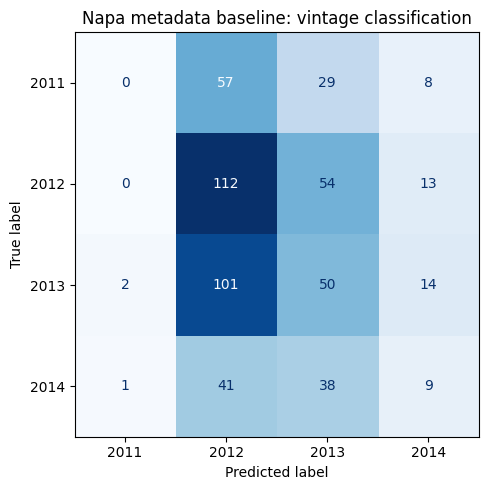

In [10]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, predicted_vintages, labels=selected_vintages,
    cmap="Blues", colorbar=False, ax=ax
)
ax.set_title("Napa metadata baseline: vintage classification")
plt.tight_layout()
plt.show()

## Bias–variance check before adding descriptions

Use only the existing training partition for five-fold stratified cross-validation. Each fold fits a fresh preprocessing pipeline, so validation rows do not influence category encoding. Report training and validation accuracy and macro F1, plus a majority-class reference on the same folds. Fold standard deviations describe variation across these splits; they are not confidence intervals or a formal bias–variance decomposition.

The learning curve varies the amount of training data within each fold while keeping validation folds fixed. The existing test partition is not used in these diagnostics or to choose changes. Since its results have already been viewed, it is not a pristine final holdout for extensive later experimentation.

Low training and validation performance suggests limited predictive signal or underfitting. A large training–validation gap suggests overfitting. Improving validation performance as training size grows suggests more data may help. These patterns guide the next experiment; they do not by themselves prove a cause.

In [11]:
from sklearn.model_selection import StratifiedKFold, cross_validate, learning_curve
from sklearn.base import clone
import numpy as np

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"accuracy": "accuracy", "macro_f1": "f1_macro"}
diagnostic_rows = []
for name, estimator in [
    ("Metadata baseline", baseline_model),
    ("Majority-class reference", DummyClassifier(strategy="most_frequent")),
]:
    scores = cross_validate(
        clone(estimator), X_train, y_train, cv=cv, scoring=scoring,
        return_train_score=True, error_score="raise"
    )
    for metric in scoring:
        train = scores[f"train_{metric}"]
        validation = scores[f"test_{metric}"]
        diagnostic_rows.append({
            "Model": name,
            "Metric": metric,
            "Train mean": train.mean(),
            "Validation mean": validation.mean(),
            "Validation SD": validation.std(ddof=1),
            "Train-validation gap": train.mean() - validation.mean(),
        })
diagnostic_results = pd.DataFrame(diagnostic_rows)
print(diagnostic_results.round(3).to_string(index=False))

# Each point uses a fraction of each CV fold's training rows.
# Shuffle rows before subsampling to avoid relying on input order.
curve_sizes, curve_train, curve_validation = learning_curve(
    clone(baseline_model), X_train, y_train, cv=cv,
    train_sizes=[0.2, 0.4, 0.6, 0.8, 1.0], scoring="f1_macro",
    shuffle=True, random_state=42, error_score="raise"
)
learning_curve_results = pd.DataFrame({
    "Training wines per fold": curve_sizes,
    "Train macro F1": curve_train.mean(axis=1),
    "Validation macro F1": curve_validation.mean(axis=1),
    "Validation SD": curve_validation.std(axis=1, ddof=1),
})
print("\nLearning curve (training partition only):")
print(learning_curve_results.round(3).to_string(index=False))

                   Model   Metric  Train mean  Validation mean  Validation SD  Train-validation gap
       Metadata baseline accuracy       0.381            0.322          0.019                 0.059
       Metadata baseline macro_f1       0.287            0.226          0.015                 0.061
Majority-class reference accuracy       0.338            0.338          0.001                 0.000
Majority-class reference macro_f1       0.126            0.126          0.000                 0.000

Learning curve (training partition only):
 Training wines per fold  Train macro F1  Validation macro F1  Validation SD
                     338           0.399                0.248          0.021
                     676           0.345                0.247          0.028
                    1014           0.317                0.235          0.024
                    1352           0.298                0.227          0.027
                    1690           0.289                0.226          0

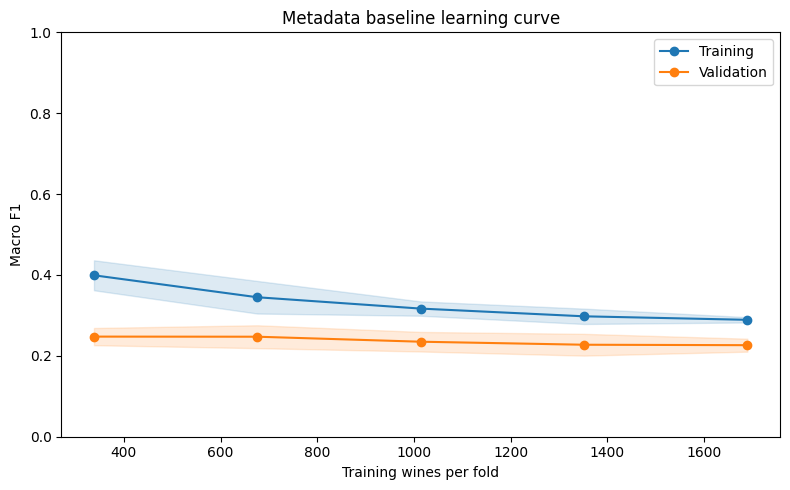

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
for label, values, color in [
    ("Training", curve_train, "tab:blue"),
    ("Validation", curve_validation, "tab:orange"),
]:
    mean = values.mean(axis=1)
    sd = values.std(axis=1, ddof=1)
    ax.plot(curve_sizes, mean, "o-", label=label, color=color)
    ax.fill_between(curve_sizes, np.clip(mean - sd, 0, 1),
                    np.clip(mean + sd, 0, 1), alpha=0.15, color=color)
ax.set(xlabel="Training wines per fold", ylabel="Macro F1",
       title="Metadata baseline learning curve", ylim=(0, 1))
ax.legend()
plt.tight_layout()
plt.show()

### Interpretation and next experiment

Five-fold CV gives training accuracy 0.381 versus validation accuracy 0.322, and training macro F1 0.287 versus validation macro F1 0.226. There is a modest generalization gap, but even training performance is low. Metadata validation accuracy is below the majority reference (0.338), although macro F1 is higher (0.226 versus 0.126).

As training size grows from 338 to 1,690 wines per fold, the train–validation macro F1 gap shrinks, but validation macro F1 does not improve (0.248 to 0.226). This experiment does not support adding more of the same metadata-only data as the first fix. Weak predictive signal or underfitting is plausible; the results do not prove that a more complex model alone would help.

Keep this baseline fixed. The next useful experiment is adding TF-IDF description features with a simple regularized classifier, evaluated on the same training-only folds. Inspect training–validation gaps before choosing more complexity or regularization. No description features have been added here.

## Add descriptions: regularized vintage classifier

Keep the established metadata baseline unchanged. Add TF-IDF description features to variety and subregion, using the exact same training/test wines and vintage classes. Remove explicit four-digit years from descriptions so the model cannot simply copy them.

TF-IDF turns words into numerical weights. Logistic regression uses L2 regularization; smaller `C` means stronger regularization. Tune `C` on five stratified folds of training data only, refitting TF-IDF and metadata encoding inside every fold. Select by validation macro F1, not by the smallest training–validation gap. The text-only notebook's best C need not be best for this combined model.

The test set has already been viewed, so these comparisons remain exploratory. Do not tune to test scores. Review language may reflect reviewer or variety differences; accuracy does not establish a causal vintage effect.

In [13]:
import re
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Add text by index; preserve the baseline split and targets exactly.
X_train_description = X_train.copy()
X_test_description = X_test.copy()
for frame in [X_train_description, X_test_description]:
    frame["description"] = wine_df.loc[frame.index, "description"].fillna("")

assert set(X_train_description.description.str.strip().str.lower()).isdisjoint(
    set(X_test_description.description.str.strip().str.lower())
)

def clean_vintage_description(text):
    return re.sub(r"\b(?:18|19|20|21)\d{2}\b", " ", text).lower()

combined_vintage_pipeline = Pipeline([
    ("features", ColumnTransformer([
        ("text", TfidfVectorizer(
            preprocessor=clean_vintage_description, lowercase=False,
            min_df=3, max_features=5000, ngram_range=(1, 1)
        ), "description"),
        ("metadata", OneHotEncoder(handle_unknown="ignore"), ["variety", "region_1"]),
    ])),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
])
combined_search = GridSearchCV(
    combined_vintage_pipeline,
    param_grid={"classifier__C": [0.01, 0.03, 0.1, 0.3, 1.0]},
    scoring={"accuracy": "accuracy", "macro_f1": "f1_macro"},
    refit="macro_f1",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    return_train_score=True, error_score="raise"
)
combined_search.fit(X_train_description, y_train)
combined_cv = pd.DataFrame(combined_search.cv_results_)
combined_regularization_results = pd.DataFrame({
    "C": combined_cv["param_classifier__C"].astype(float),
    "Train macro F1": combined_cv["mean_train_macro_f1"],
    "Validation macro F1": combined_cv["mean_test_macro_f1"],
    "Validation F1 SD": combined_cv["std_test_macro_f1"],
    "Validation accuracy": combined_cv["mean_test_accuracy"],
})
combined_regularization_results["F1 gap"] = (
    combined_regularization_results["Train macro F1"]
    - combined_regularization_results["Validation macro F1"]
)
print(combined_regularization_results.round(3).to_string(index=False))
print("\nSelected C:", combined_search.best_params_["classifier__C"])
# GridSearchCV refits the selected pipeline on the full training partition.
description_vintage_model = combined_search.best_estimator_

   C  Train macro F1  Validation macro F1  Validation F1 SD  Validation accuracy  F1 gap
0.01           0.225                0.191             0.013                0.350   0.034
0.03           0.253                0.209             0.007                0.362   0.044
0.10           0.416                0.286             0.016                0.397   0.130
0.30           0.619                0.374             0.017                0.431   0.244
1.00           0.811                0.423             0.022                0.451   0.388

Selected C: 1.0


                                         Test accuracy  Test macro F1
Model                                                                
Established metadata baseline                    0.323          0.222
Descriptions + metadata (CV-selected C)          0.463          0.421

Description + metadata per-vintage performance:
              precision    recall  f1-score   support

        2011       0.55      0.33      0.41        94
        2012       0.49      0.61      0.54       179
        2013       0.43      0.53      0.47       167
        2014       0.38      0.19      0.25        89

    accuracy                           0.46       529
   macro avg       0.46      0.41      0.42       529
weighted avg       0.46      0.46      0.45       529



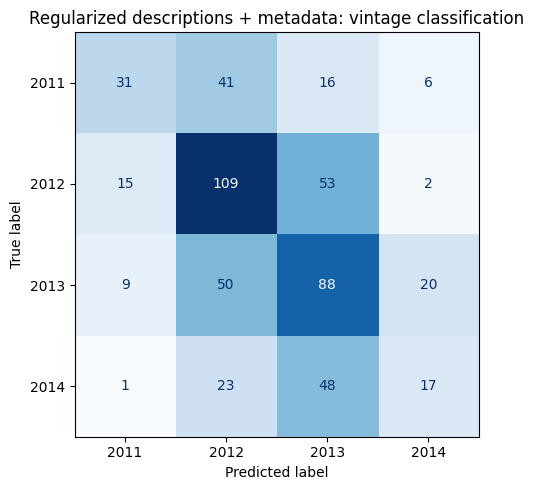

In [14]:
description_vintage_predictions = description_vintage_model.predict(X_test_description)
baseline_predictions = baseline_model.predict(X_test)
comparison = []
for name, predictions in [
    ("Established metadata baseline", baseline_predictions),
    ("Descriptions + metadata (CV-selected C)", description_vintage_predictions),
]:
    comparison.append({
        "Model": name,
        "Test accuracy": accuracy_score(y_test, predictions),
        "Test macro F1": f1_score(y_test, predictions, average="macro", zero_division=0),
    })
print(pd.DataFrame(comparison).set_index("Model").round(3).to_string())
print("\nDescription + metadata per-vintage performance:")
print(classification_report(y_test, description_vintage_predictions,
                            labels=selected_vintages, zero_division=0))
fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, description_vintage_predictions, labels=selected_vintages,
    cmap="Blues", colorbar=False, ax=ax
)
ax.set_title("Regularized descriptions + metadata: vintage classification")
plt.tight_layout()
plt.show()